# CM Stable

            Differential Evolution + LSTSQ Fit Parameter Table (3-Channel CM)             
Parameter    | Fitted Value | Description
------------------------------------------------------------------------------------------
K11          |     -2.56223 | K-matrix element (1,1)
K12          |      1.22707 | K-matrix element (1,2)
K13          |     -0.41157 | K-matrix element (1,3)
K22          |      0.71014 | K-matrix element (2,2)
K23          |     -1.03083 | K-matrix element (2,3)
K33          |     -1.47863 | K-matrix element (3,3)
alpha2       |     -5.84439 | Channel 2 production vector ratio
alpha3       |    -14.10198 | Channel 3 production vector ratio
Na           |     21.89858 | Spectrum normalization factor
------------------------------------------------------------------------------------------
Total Chi^2       : 53.482
Degrees of Freedom: 48
Chi^2 / dof       : 1.114

Automated Riemann Sheet Pole Findings:
  [Sheet II (-, +, +) [btt]] W = 3.874492 + i(0.000426) GeV | P

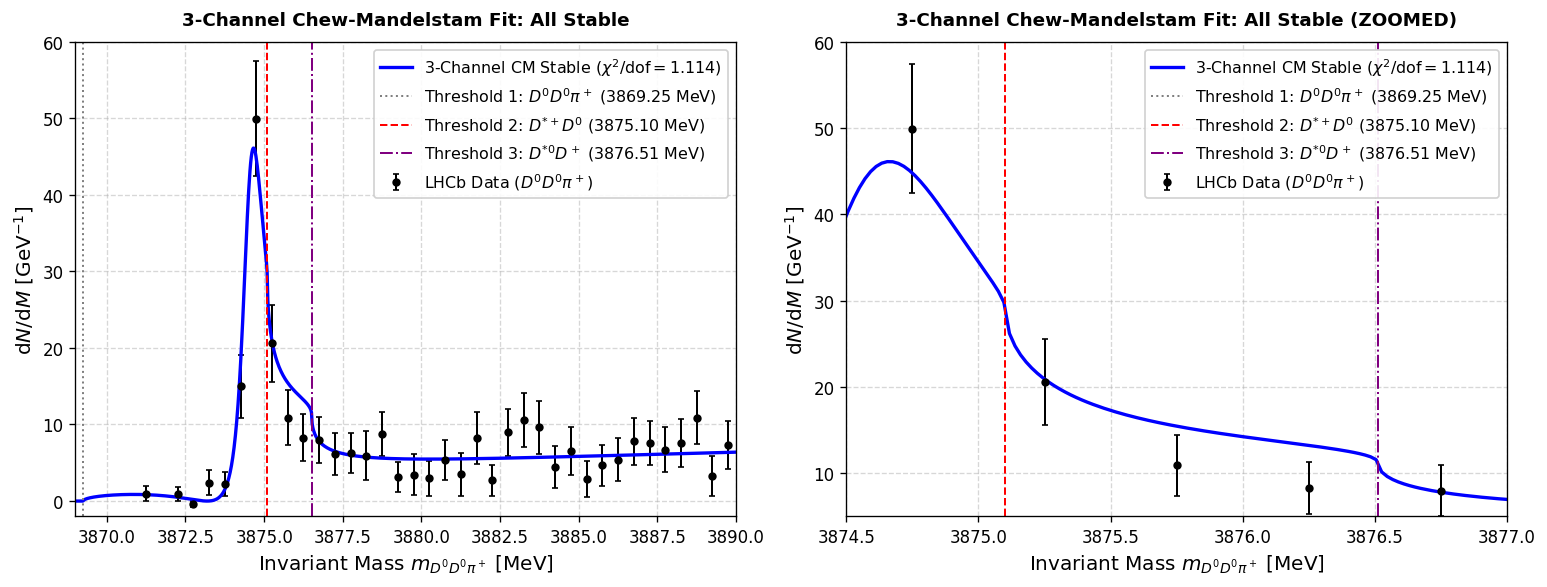

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution, root

# ---------------------------------------------------------
# 1. Physical Constants & Isobar Channel Thresholds (GeV)
# ---------------------------------------------------------
m_D0 = 1.86484
m_Dstar = 2.01026
m_pion = 0.13957
m_Dplus = 1.86966
m_Dstar0 = 2.00685

# 3 Isobar Channels (All Hadrons Stable)
M1, m1 = m_D0 + m_pion, m_D0
M2, m2 = m_Dstar, m_D0
M3, m3 = m_Dstar0, m_Dplus

# ---------------------------------------------------------
# 2. Kinematics & Chew-Mandelstam Loop Functions
# ---------------------------------------------------------
def sqrt_rhc(z):
    z_c = np.asarray(z, dtype=np.complex128)
    r = np.abs(z_c)
    theta = np.angle(z_c)
    theta = np.where(theta < 0, theta + 2.0 * np.pi, theta)

    res = np.sqrt(r) * np.exp(1j * theta / 2.0)
    return res if isinstance(z, np.ndarray) else res.item()

def chew_mandelstam(s_val, M, m, sheet_sign=+1):
    s_c = np.asarray(s_val, dtype=np.complex128) + 1e-12j
    sth = (M + m) ** 2
    s_diff = (M - m) ** 2
    lam = (s_c - sth) * (s_c - s_diff)
    rho = np.sqrt(lam) / s_c

    if sheet_sign == -1:
        rho = -rho

    term1 = (
        (M**2 - m**2) / (np.pi * s_c) - (M**2 + m**2) / (np.pi * (M**2 - m**2))
    ) * np.log(m / M)
    term2 = 1.0 / np.pi
    num = sqrt_rhc(sth - s_c) - np.sqrt(s_diff - s_c)
    den = sqrt_rhc(sth - s_c) + np.sqrt(s_diff - s_c)
    term3 = (rho / np.pi) * np.log(num / den)
    return term1 + term2 + term3

def p1_func(s):
    sth = (M1 + m1) ** 2
    s_diff = (M1 - m1) ** 2
    lam = (s + 0j - sth) * (s + 0j - s_diff)
    return np.real(np.sqrt(lam)) / (2.0 * np.sqrt(s))

# ---------------------------------------------------------
# Optimized T-matrix calculation
# ---------------------------------------------------------
def compute_t_matrix_elements(E_MeV, K_params, s1=+1, s2=+1, s3=+1):
    K11, K12, K13, K22, K23, K33 = K_params
    E_GeV = np.asarray(E_MeV, dtype=np.complex128) / 1000.0
    s = E_GeV**2

    K_mat = np.array([[K11, K12, K13], [K12, K22, K23], [K13, K23, K33]], dtype=np.complex128)

    try:
        K_inv = np.linalg.inv(K_mat)
    except np.linalg.LinAlgError:
        return None, None, None, None

    C1 = chew_mandelstam(s, M1, m1, sheet_sign=s1)
    C2 = chew_mandelstam(s, M2, m2, sheet_sign=s2)
    C3 = chew_mandelstam(s, M3, m3, sheet_sign=s3)

    M_mat = np.broadcast_to(K_inv, (np.size(s), 3, 3)).copy()
    M_mat[:, 0, 0] -= C1.ravel()
    M_mat[:, 1, 1] -= C2.ravel()
    M_mat[:, 2, 2] -= C3.ravel()

    try:
        T_mat = np.linalg.inv(M_mat)
        T11 = T_mat[:, 0, 0]
        T12 = T_mat[:, 0, 1]
        T13 = T_mat[:, 0, 2]
    except np.linalg.LinAlgError:
        T11_list, T12_list, T13_list = [], [], []

        for i in range(np.size(s)):
            M_i = K_inv.copy()
            M_i[0, 0] -= np.ravel(C1)[i]
            M_i[1, 1] -= np.ravel(C2)[i]
            M_i[2, 2] -= np.ravel(C3)[i]

            try:
                T_i = np.linalg.inv(M_i)
                T11_list.append(T_i[0, 0])
                T12_list.append(T_i[0, 1])
                T13_list.append(T_i[0, 2])
            except np.linalg.LinAlgError:
                T11_list.append(0.0)
                T12_list.append(0.0)
                T13_list.append(0.0)

        T11 = np.asarray(T11_list)
        T12 = np.asarray(T12_list)
        T13 = np.asarray(T13_list)

    p1 = p1_func(s)
    return np.asarray(p1), np.asarray(T11), np.asarray(T12), np.asarray(T13)

# ---------------------------------------------------------
# Optimized determinant calculation
# ---------------------------------------------------------
def det_M_matrix(W_complex, K_params, s1=+1, s2=+1, s3=+1):
    K11, K12, K13, K22, K23, K33 = K_params
    K_mat = np.array([[K11, K12, K13], [K12, K22, K23], [K13, K23, K33]], dtype=np.complex128)

    try:
        K_inv = np.linalg.inv(K_mat)
    except np.linalg.LinAlgError:
        return 1e10

    s = np.asarray(W_complex, dtype=np.complex128) ** 2
    C1 = chew_mandelstam(s, M1, m1, sheet_sign=s1)
    C2 = chew_mandelstam(s, M2, m2, sheet_sign=s2)
    C3 = chew_mandelstam(s, M3, m3, sheet_sign=s3)

    a = K_inv[0, 0] - C1
    d = K_inv[1, 1] - C2
    f = K_inv[2, 2] - C3
    b = K_inv[0, 1]
    c = K_inv[0, 2]
    e = K_inv[1, 2]

    return a * d * f + 2.0 * b * c * e - a * e**2 - d * c**2 - f * b**2

# ---------------------------------------------------------
# 3. Load Dataset
# ---------------------------------------------------------
data_path = r"C:\Users\ermag\Desktop\NHP\ResLog\Sept2026\Fig1.csv"
df_data = pd.read_csv(data_path, comment="#")

data_mass_MeV = df_data.iloc[:, 0].values * 1000.0
data_yield = df_data.iloc[:, 3].values
data_err = df_data.iloc[:, 4].values

# ---------------------------------------------------------
# 4. VarPro LSTSQ Optimization
# ---------------------------------------------------------
def fit_linear_parameters_lstsq(K_params, E_MeV, y_data=None, y_err=None):
    p1, T11, T12, T13 = compute_t_matrix_elements(E_MeV, K_params)

    if p1 is None:
        return (1e10, 0.0, 0.0, 0.0, np.zeros_like(E_MeV))

    if y_data is None:
        return p1, T11, T12, T13

    p1_real = np.real(p1)
    abs_T11_sq = np.abs(T11) ** 2
    abs_T12_sq = np.abs(T12) ** 2
    abs_T13_sq = np.abs(T13) ** 2

    f11 = p1_real * abs_T11_sq
    f22 = p1_real * abs_T12_sq
    f33 = p1_real * abs_T13_sq
    f12 = p1_real * 2.0 * np.real(T11 * np.conj(T12))
    f13 = p1_real * 2.0 * np.real(T11 * np.conj(T13))
    f23 = p1_real * 2.0 * np.real(T12 * np.conj(T13))

    A_mat = np.column_stack([f11, f12, f13, f22, f33, f23])
    A_mat /= y_err[:, None]
    b_vec = y_data / y_err
    A_mat = np.real(A_mat)
    b_vec = np.real(b_vec)

    w, _, _, _ = np.linalg.lstsq(A_mat, b_vec, rcond=1e-10)

    Na = float(max(w[0], 1e-4))
    alpha2 = float(w[1] / Na)
    alpha3 = float(w[2] / Na)

    F1 = T11 + alpha2 * T12 + alpha3 * T13
    yield_pred = np.real(Na * p1 * np.abs(F1) ** 2)

    residuals = (y_data - yield_pred) / y_err
    chi2 = float(np.sum(residuals**2))

    return (chi2, Na, alpha2, alpha3, yield_pred)

def de_cost_function(K_params):
    chi2, _, _, _, _ = fit_linear_parameters_lstsq(K_params, data_mass_MeV, data_yield, data_err)

    if not np.isfinite(chi2):
        return 1e10
    return float(np.real(chi2))

# ---------------------------------------------------------
# 4A. Global Differential Evolution
# ---------------------------------------------------------
res_de = differential_evolution(
    de_cost_function, 
    bounds=[(-5.0, 5.0)] * 6, 
    seed=42, 
    maxiter=1200, 
    popsize=20
)

K_opt = res_de.x
chi2_opt, Na_opt, a2_opt, a3_opt, yield_fit = fit_linear_parameters_lstsq(K_opt, data_mass_MeV, data_yield, data_err)

dof = len(data_yield) - 9
chi2_dof = chi2_opt / dof
p_opt = list(K_opt) + [a2_opt, a3_opt, Na_opt]

# ---------------------------------------------------------
# 5. Automated Pole Search Across All 8 Riemann Sheets
# ---------------------------------------------------------
def identify_rs_3channel(s1, s2, s3):
    s1_s = "+" if s1 == +1 else "-"
    s2_s = "+" if s2 == +1 else "-"
    s3_s = "+" if s3 == +1 else "-"
    sheet_code = f"({s1_s}, {s2_s}, {s3_s})"
    sheet_map = {
        (+1, +1, +1): f"Sheet I {sheet_code} [ttt]",
        (-1, +1, +1): f"Sheet II {sheet_code} [btt]",
        (-1, -1, +1): f"Sheet III {sheet_code} [bbt]",
        (-1, -1, -1): f"Sheet IV {sheet_code} [bbb]",
        (+1, -1, +1): f"Sheet V {sheet_code} [tbt]",
        (+1, +1, -1): f"Sheet VI {sheet_code} [ttb]",
        (-1, +1, -1): f"Sheet VII {sheet_code} [btb]",
        (+1, -1, -1): f"Sheet VIII {sheet_code} [tbb]",
    }
    return sheet_map.get((s1, s2, s3), f"Sheet {sheet_code}")

def cauchy_contour_pole_refine(W_center, K_params, s1, s2, s3, r=2e-4, n_pts=64):
    angles = np.linspace(0, 2 * np.pi, n_pts, endpoint=False)
    circle = W_center + r * np.exp(1j * angles)
    dW = 1j * r * np.exp(1j * angles) * (2 * np.pi / n_pts)

    D_vals = det_M_matrix(circle, K_params, s1=s1, s2=s2, s3=s3)
    I_num = np.sum((circle / D_vals) * dW)
    I_den = np.sum((1.0 / D_vals) * dW)
    return I_num / I_den if abs(I_den) > 1e-4 else W_center

def auto_search_all_sheets(K_params):
    sheets = [
        (+1, +1, +1),
        (-1, +1, +1),
        (-1, -1, +1),
        (-1, -1, -1),
        (+1, -1, +1),
        (+1, +1, -1),
        (-1, +1, -1),
        (+1, -1, -1),
    ]

    E_re = np.linspace(3.860, 3.890, 150)
    E_im = np.linspace(-0.050, 0.002, 150)
    grid_R, grid_I = np.meshgrid(E_re, E_im)
    W_grid = grid_R + 1j * grid_I
    all_poles = []

    for s1, s2, s3 in sheets:
        det_grid_complex = det_M_matrix(W_grid, K_params, s1=s1, s2=s2, s3=s3)
        det_grid = np.abs(det_grid_complex)

        min_mask = (
            (det_grid < np.roll(det_grid, 1, axis=0)) &
            (det_grid < np.roll(det_grid, -1, axis=0)) &
            (det_grid < np.roll(det_grid, 1, axis=1)) &
            (det_grid < np.roll(det_grid, -1, axis=1))
        )
        min_idx = np.argwhere(min_mask)

        if min_idx.size == 0:
            continue

        local_mins = det_grid[min_idx[:, 0], min_idx[:, 1]]
        viable = min_idx[local_mins < 5.0]

        if viable.size == 0:
            continue

        best = viable[np.argmin(det_grid[viable[:, 0], viable[:, 1]])]
        W_seed = W_grid[best[0], best[1]]

        W_cauchy = cauchy_contour_pole_refine(W_seed, K_params, s1, s2, s3)

        def det_func(x):
            val = det_M_matrix(x[0] + 1j * x[1], K_params, s1=s1, s2=s2, s3=s3)
            return np.array([val.real, val.imag], dtype=float)

        sol = root(det_func, [W_cauchy.real, W_cauchy.imag], method="hybr")

        if sol.success:
            W_pole = sol.x[0] + 1j * sol.x[1]
            res = abs(det_M_matrix(W_pole, K_params, s1=s1, s2=s2, s3=s3))

            if (
                res < 1e-5
                and 3.85 <= W_pole.real <= 3.90
                and -0.1 <= W_pole.imag <= 0.005
            ):
                sheet_label = identify_rs_3channel(s1, s2, s3)
                duplicate = any(np.isclose(W_pole, p["W"], atol=1e-4) for p in all_poles)

                if not duplicate:
                    all_poles.append({
                        "W": W_pole,
                        "sheet": sheet_label,
                        "s1": s1,
                        "s2": s2,
                        "s3": s3,
                    })

    return all_poles

poles_found = auto_search_all_sheets(K_opt)

# ---------------------------------------------------------
# 6. Summary Table Output
# ---------------------------------------------------------
param_names = ["K11", "K12", "K13", "K22", "K23", "K33", "alpha2", "alpha3", "Na"]
descriptions = [
    "K-matrix element (1,1)",
    "K-matrix element (1,2)",
    "K-matrix element (1,3)",
    "K-matrix element (2,2)",
    "K-matrix element (2,3)",
    "K-matrix element (3,3)",
    "Channel 2 production vector ratio",
    "Channel 3 production vector ratio",
    "Spectrum normalization factor",
]

print("=" * 90)
print(f"{'Differential Evolution + LSTSQ Fit Parameter Table (3-Channel CM)':^90}")
print("=" * 90)
print(f"{'Parameter':<12} | {'Fitted Value':>12} | {'Description'}")
print("-" * 90)

for name, val, desc in zip(param_names, p_opt, descriptions):
    print(f"{name:<12} | {val:12.5f} | {desc}")

print("-" * 90)
print(f"Total Chi^2       : {chi2_opt:.3f}")
print(f"Degrees of Freedom: {dof}")
print(f"Chi^2 / dof       : {chi2_dof:.3f}")
print("=" * 90)

print("\nAutomated Riemann Sheet Pole Findings:")
if len(poles_found) == 0:
    print("  No poles detected within search boundary.")
else:
    for p in poles_found:
        W_p = p["W"]
        M_R = W_p.real * 1000.0
        Gamma_R = -2.0 * W_p.imag * 1000.0
        print(
            f"  [{p['sheet']}] "
            f"W = {W_p.real:.6f} "
            f"+ i({W_p.imag:.6f}) GeV | "
            f"Pole Mass = {M_R:.2f} MeV, "
            f"Width = {Gamma_R:.2f} MeV"
        )

print("=" * 90)

# ---------------------------------------------------------
# 7. Plotting Fit Spectrum
# ---------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
m_th1 = (M1 + m1) * 1000.0
m_th2 = (M2 + m2) * 1000.0
m_th3 = (M3 + m3) * 1000.0

# Fig (a)
E_fine_MeV = np.linspace(3869.0, 3890.0, 1000)
p1_f, T11_f, T12_f, T13_f = fit_linear_parameters_lstsq(K_opt, E_fine_MeV)
F1_f = T11_f + a2_opt * T12_f + a3_opt * T13_f
yield_fit_fine = np.real(Na_opt * p1_f * np.abs(F1_f) ** 2)
chi2_str = f"{chi2_dof:.3f}"
ax[0].errorbar(data_mass_MeV, data_yield, yerr=data_err, fmt="o", color="black", ecolor="black", elinewidth=1.2, capsize=2, markersize=4, label=r"LHCb Data ($D^0 D^0 \pi^+$)")
ax[0].plot(E_fine_MeV, yield_fit_fine, color="blue", lw=2, label=(r"3-Channel CM Stable " r"($\chi^2/\mathrm{dof} = " + chi2_str + r"$)"))
ax[0].axvline(m_th1, color="gray", linestyle=":", lw=1.2, label=(r"Threshold 1: $D^0 D^0 \pi^+$ (" + f"{m_th1:.2f}" + r" MeV)"))
ax[0].axvline(m_th2, color="red", linestyle="--", lw=1.2, label=(r"Threshold 2: $D^{*+} D^0$ (" + f"{m_th2:.2f}" + r" MeV)"))
ax[0].axvline(m_th3, color="purple", linestyle="-.", lw=1.2, label=(r"Threshold 3: $D^{*0} D^+$ (" + f"{m_th3:.2f}" + r" MeV)"))
ax[0].set_title(r"3-Channel Chew-Mandelstam Fit: All Stable", fontsize=11, fontweight="bold", pad=10)
ax[0].set_xlabel(r"Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]", fontsize=12)
ax[0].set_ylabel(r"$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]", fontsize=12)
ax[0].set_xlim(3869, 3890)
ax[0].set_ylim(-2, 60)
ax[0].grid(True, linestyle="--", alpha=0.5)
ax[0].legend(frameon=True, facecolor="white", framealpha=0.9, fontsize=9.5)

# Fig (b)
E_fine_MeV_ZOOM = np.linspace(3869.0, 3890.0, 1000)
p1_f, T11_f, T12_f, T13_f = fit_linear_parameters_lstsq(K_opt, E_fine_MeV_ZOOM)
F1_f = T11_f + a2_opt * T12_f + a3_opt * T13_f
yield_fit_fine_ZOOM = np.real(Na_opt * p1_f * np.abs(F1_f) ** 2)
chi2_str = f"{chi2_dof:.3f}"
ax[1].errorbar(data_mass_MeV, data_yield, yerr=data_err, fmt="o", color="black", ecolor="black", elinewidth=1.2, capsize=2, markersize=4, label=r"LHCb Data ($D^0 D^0 \pi^+$)")
ax[1].plot(E_fine_MeV_ZOOM, yield_fit_fine_ZOOM, color="blue", lw=2, label=(r"3-Channel CM Stable " r"($\chi^2/\mathrm{dof} = " + chi2_str + r"$)"))
ax[1].axvline(m_th1, color="gray", linestyle=":", lw=1.2, label=(r"Threshold 1: $D^0 D^0 \pi^+$ (" + f"{m_th1:.2f}" + r" MeV)"))
ax[1].axvline(m_th2, color="red", linestyle="--", lw=1.2, label=(r"Threshold 2: $D^{*+} D^0$ (" + f"{m_th2:.2f}" + r" MeV)"))
ax[1].axvline(m_th3, color="purple", linestyle="-.", lw=1.2, label=(r"Threshold 3: $D^{*0} D^+$ (" + f"{m_th3:.2f}" + r" MeV)"))
ax[1].set_title(r"3-Channel Chew-Mandelstam Fit: All Stable (ZOOMED)", fontsize=11, fontweight="bold", pad=10)
ax[1].set_xlabel(r"Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]", fontsize=12)
ax[1].set_ylabel(r"$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]", fontsize=12)
ax[1].set_xlim(3874.5, 3877.0)
ax[1].set_ylim(5, 60)
ax[1].grid(True, linestyle="--", alpha=0.5)
ax[1].legend(frameon=True, facecolor="white", framealpha=0.9, fontsize=9.5)

plt.tight_layout()
plt.show()


# CM Unstable

            Differential Evolution + LSTSQ Fit Parameter Table (3-Channel CM)             
Parameter    | Fitted Value | Description
------------------------------------------------------------------------------------------
K11          |     -0.59740 | K-matrix element (1,1)
K12          |     -0.45879 | K-matrix element (1,2)
K13          |     -0.57171 | K-matrix element (1,3)
K22          |      0.02453 | K-matrix element (2,2)
K23          |      2.56658 | K-matrix element (2,3)
K33          |     -3.76974 | K-matrix element (3,3)
alpha2       |      1.01789 | Channel 2 production vector ratio
alpha3       |     -1.21137 | Channel 3 production vector ratio
Na           |    131.86903 | Spectrum normalization factor
------------------------------------------------------------------------------------------
Total Chi^2       : 47.840
Degrees of Freedom: 48
Chi^2 / dof       : 0.997

Automated Riemann Sheet Pole Findings:
  [Sheet II (-, +, +) [btt]] W = 3.874644 + i(0.000351) GeV | P

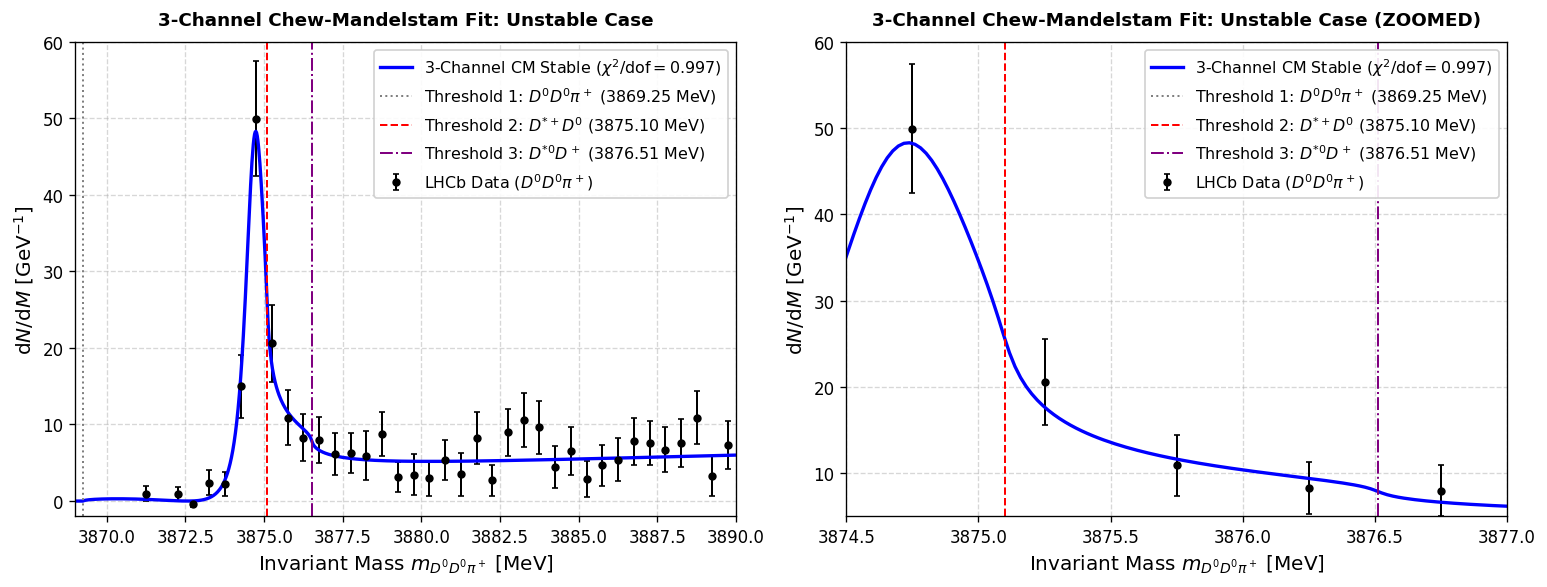

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import differential_evolution, root

# =========================================================
# 1. Physical Constants & Isobar Channel Thresholds (GeV)
# =========================================================

m_D0 = 1.86484
m_Dstar = 2.01026
m_pion = 0.13957
m_Dplus = 1.86966
m_Dstar0 = 2.00685

Gamma_Dstar_plus = 0.0000834
Gamma_Dstar_0 = 0.0000559

# ---------------------------------------------------------
# 3 Isobar Channels
# ---------------------------------------------------------

# Channel 1: (D0 pi+) + D0
M1, m1 = (m_D0 + m_pion, m_D0)

# Channel 2: D*+ + D0
M2, m2 = (m_Dstar - 1j * Gamma_Dstar_plus / 2.0, m_D0)

# Channel 3: D*0 + D+
M3, m3 = (m_Dstar0 - 1j * Gamma_Dstar_0 / 2.0, m_Dplus)

# =========================================================
# 2. Kinematics & Chew-Mandelstam Loop Functions
# =========================================================

def sqrt_rhc(z):
    z_c = np.asarray(z, dtype=np.complex128)
    r = np.abs(z_c)
    theta = np.angle(z_c)
    theta = np.where(theta < 0, theta + 2.0 * np.pi, theta)
    res = np.sqrt(r) * np.exp(1j * theta / 2.0)
    return res if isinstance(z, np.ndarray) else res.item()

def chew_mandelstam(s_val, M, m, sheet_sign=+1):
    s_c = np.asarray(s_val, dtype=np.complex128) + 1e-12j
    sth = (M + m) ** 2
    s_diff = (M - m) ** 2
    lam = (s_c - sth) * (s_c - s_diff)
    rho = np.sqrt(lam) / s_c
    if sheet_sign == -1:
        rho = -rho

    term1 = (
        ((M**2 - m**2) / (np.pi * s_c)) - ((M**2 + m**2) / (np.pi * (M**2 - m**2)))
    ) * np.log(m / M)

    term2 = 1.0 / np.pi
    num = sqrt_rhc(sth - s_c) - np.sqrt(s_diff - s_c)
    den = sqrt_rhc(sth - s_c) + np.sqrt(s_diff - s_c)
    term3 = (rho / np.pi) * np.log(num / den)

    return term1 + term2 + term3

def p1_func(s):
    sth = (M1 + m1) ** 2
    s_diff = (M1 - m1) ** 2
    lam = (s + 0j - sth) * (s + 0j - s_diff)
    return np.real(np.sqrt(lam)) / (2.0 * np.sqrt(s))

# =========================================================
# 3. Optimized T-Matrix
# =========================================================

def compute_t_matrix_elements(E_MeV, K_params, s1=+1, s2=+1, s3=+1):
    K11, K12, K13, K22, K23, K33 = K_params
    E_GeV = np.asarray(E_MeV, dtype=np.complex128) / 1000.0
    s = E_GeV**2

    K_mat = np.array([[K11, K12, K13], [K12, K22, K23], [K13, K23, K33]], dtype=np.complex128)

    try:
        K_inv = np.linalg.inv(K_mat)
    except np.linalg.LinAlgError:
        return (None, None, None, None)

    C1 = chew_mandelstam(s, M1, m1, sheet_sign=s1)
    C2 = chew_mandelstam(s, M2, m2, sheet_sign=s2)
    C3 = chew_mandelstam(s, M3, m3, sheet_sign=s3)

    n = np.size(s)
    M_mat = np.broadcast_to(K_inv, (n, 3, 3)).copy()
    M_mat[:, 0, 0] -= np.ravel(C1)
    M_mat[:, 1, 1] -= np.ravel(C2)
    M_mat[:, 2, 2] -= np.ravel(C3)

    try:
        T_mat = np.linalg.inv(M_mat)
        T11 = T_mat[:, 0, 0]
        T12 = T_mat[:, 0, 1]
        T13 = T_mat[:, 0, 2]
    except np.linalg.LinAlgError:
        T11 = np.zeros(n, dtype=np.complex128)
        T12 = np.zeros(n, dtype=np.complex128)
        T13 = np.zeros(n, dtype=np.complex128)
        for i in range(n):
            try:
                T_i = np.linalg.inv(M_mat[i])
                T11[i] = T_i[0, 0]
                T12[i] = T_i[0, 1]
                T13[i] = T_i[0, 2]
            except np.linalg.LinAlgError:
                pass

    p1 = p1_func(s)
    return (np.asarray(p1), np.asarray(T11), np.asarray(T12), np.asarray(T13))

# =========================================================
# 4. Optimized Determinant
# =========================================================

def det_M_matrix(W_complex, K_params, s1=+1, s2=+1, s3=+1):
    K11, K12, K13, K22, K23, K33 = K_params
    K_mat = np.array([[K11, K12, K13], [K12, K22, K23], [K13, K23, K33]], dtype=np.complex128)

    try:
        K_inv = np.linalg.inv(K_mat)
    except np.linalg.LinAlgError:
        return 1e10

    W_complex = np.asarray(W_complex, dtype=np.complex128)
    s = W_complex**2

    C1 = chew_mandelstam(s, M1, m1, sheet_sign=s1)
    C2 = chew_mandelstam(s, M2, m2, sheet_sign=s2)
    C3 = chew_mandelstam(s, M3, m3, sheet_sign=s3)

    a = K_inv[0, 0] - C1
    d = K_inv[1, 1] - C2
    f = K_inv[2, 2] - C3
    b = K_inv[0, 1]
    c = K_inv[0, 2]
    e = K_inv[1, 2]

    return a * d * f + 2.0 * b * c * e - a * e**2 - d * c**2 - f * b**2

# =========================================================
# 5. Load Dataset
# =========================================================

data_path = r"C:\Users\ermag\Desktop\NHP" r"\ResLog\Sept2026\Fig1.csv"
df_data = pd.read_csv(data_path, comment="#")

data_mass_MeV = df_data.iloc[:, 0].values * 1000.0
data_yield = df_data.iloc[:, 3].values
data_err = df_data.iloc[:, 4].values

# =========================================================
# 6. Variable Projection Least Squares
# =========================================================

def fit_linear_parameters_lstsq(K_params, E_MeV, y_data=None, y_err=None):
    p1, T11, T12, T13 = compute_t_matrix_elements(E_MeV, K_params)

    if p1 is None:
        return (1e10, 0.0, 0.0, 0.0, np.zeros_like(E_MeV))

    if y_data is None:
        return (p1, T11, T12, T13)

    p1_real = np.real(p1)
    f11 = p1_real * np.abs(T11) ** 2
    f22 = p1_real * np.abs(T12) ** 2
    f33 = p1_real * np.abs(T13) ** 2
    f12 = p1_real * 2.0 * np.real(T11 * np.conj(T12))
    f13 = p1_real * 2.0 * np.real(T11 * np.conj(T13))
    f23 = p1_real * 2.0 * np.real(T12 * np.conj(T13))

    A_mat = np.column_stack([f11, f12, f13, f22, f33, f23])
    A_mat /= y_err[:, None]
    b_vec = y_data / y_err
    A_mat = np.real(A_mat)
    b_vec = np.real(b_vec)

    w, _, _, _ = np.linalg.lstsq(A_mat, b_vec, rcond=1e-10)

    Na = float(max(w[0], 1e-4))
    alpha2 = float(w[1] / Na)
    alpha3 = float(w[2] / Na)

    F1 = T11 + alpha2 * T12 + alpha3 * T13
    yield_pred = np.real(Na * p1 * np.abs(F1) ** 2)
    residuals = (y_data - yield_pred) / y_err
    chi2 = float(np.sum(residuals**2))

    return (chi2, Na, alpha2, alpha3, yield_pred)

# =========================================================
# 7. Differential Evolution Cost Function
# =========================================================

def de_cost_function(K_params):
    chi2, _, _, _, _ = fit_linear_parameters_lstsq(
        K_params, data_mass_MeV, data_yield, data_err
    )
    if not np.isfinite(chi2):
        return 1e10
    return float(np.real(chi2))

# =========================================================
# 8. Global Differential Evolution
# =========================================================

res_de = differential_evolution(
    de_cost_function, bounds=[(-5.0, 5.0)] * 6, seed=42, maxiter=1200, popsize=20
)

K_opt = res_de.x

# =========================================================
# 9. Final Fit
# =========================================================

chi2_opt, Na_opt, a2_opt, a3_opt, yield_fit = fit_linear_parameters_lstsq(
    K_opt, data_mass_MeV, data_yield, data_err
)

dof = len(data_yield) - 9
chi2_dof = chi2_opt / dof
p_opt = list(K_opt) + [a2_opt, a3_opt, Na_opt]

# =========================================================
# 10. Riemann Sheet Identification
# =========================================================

def identify_rs_3channel(s1, s2, s3):
    s1_s = "+" if s1 == +1 else "-"
    s2_s = "+" if s2 == +1 else "-"
    s3_s = "+" if s3 == +1 else "-"
    sheet_code = f"({s1_s}, {s2_s}, {s3_s})"

    sheet_map = {
        (+1, +1, +1): f"Sheet I {sheet_code} [ttt]",
        (-1, +1, +1): f"Sheet II {sheet_code} [btt]",
        (-1, -1, +1): f"Sheet III {sheet_code} [bbt]",
        (-1, -1, -1): f"Sheet IV {sheet_code} [bbb]",
        (+1, -1, +1): f"Sheet V {sheet_code} [tbt]",
        (+1, +1, -1): f"Sheet VI {sheet_code} [ttb]",
        (-1, +1, -1): f"Sheet VII {sheet_code} [btb]",
        (+1, -1, -1): f"Sheet VIII {sheet_code} [tbb]",
    }
    return sheet_map.get((s1, s2, s3), f"Sheet {sheet_code}")

# =========================================================
# 11. Cauchy Contour Pole Refinement
# =========================================================

def cauchy_contour_pole_refine(W_center, K_params, s1, s2, s3, r=2e-4, n_pts=64):
    angles = np.linspace(0, 2.0 * np.pi, n_pts, endpoint=False)
    circle = W_center + r * np.exp(1j * angles)
    dW = 1j * r * np.exp(1j * angles) * (2.0 * np.pi / n_pts)

    D_vals = det_M_matrix(circle, K_params, s1=s1, s2=s2, s3=s3)
    I_num = np.sum((circle / D_vals) * dW)
    I_den = np.sum((1.0 / D_vals) * dW)

    if abs(I_den) > 1e-4:
        return I_num / I_den
    return W_center

# =========================================================
# 12. Automated Pole Search Across All 8 Sheets
# =========================================================

def auto_search_all_sheets(K_params):
    sheets = [
        (+1, +1, +1),
        (-1, +1, +1),
        (-1, -1, +1),
        (-1, -1, -1),
        (+1, -1, +1),
        (+1, +1, -1),
        (-1, +1, -1),
        (+1, -1, -1),
    ]

    E_re = np.linspace(3.860, 3.890, 150)
    E_im = np.linspace(-0.050, 0.002, 150)
    grid_R, grid_I = np.meshgrid(E_re, E_im)
    W_grid = grid_R + 1j * grid_I
    all_poles = []

    for s1, s2, s3 in sheets:
        det_grid_complex = det_M_matrix(W_grid, K_params, s1=s1, s2=s2, s3=s3)
        det_grid = np.abs(det_grid_complex)

        min_mask = (
            (det_grid < np.roll(det_grid, 1, axis=0)) &
            (det_grid < np.roll(det_grid, -1, axis=0)) &
            (det_grid < np.roll(det_grid, 1, axis=1)) &
            (det_grid < np.roll(det_grid, -1, axis=1))
        )
        min_idx = np.argwhere(min_mask)

        if min_idx.size == 0:
            continue

        local_mins = det_grid[min_idx[:, 0], min_idx[:, 1]]
        viable = min_idx[local_mins < 5.0]

        if viable.size == 0:
            continue

        best = viable[np.argmin(det_grid[viable[:, 0], viable[:, 1]])]
        W_seed = W_grid[best[0], best[1]]

        W_cauchy = cauchy_contour_pole_refine(W_seed, K_params, s1, s2, s3)

        def det_func(x):
            val = det_M_matrix(x[0] + 1j * x[1], K_params, s1=s1, s2=s2, s3=s3)
            return np.array([val.real, val.imag], dtype=float)

        sol = root(det_func, [W_cauchy.real, W_cauchy.imag], method="hybr")

        if sol.success:
            W_pole = sol.x[0] + 1j * sol.x[1]
            res = abs(det_M_matrix(W_pole, K_params, s1=s1, s2=s2, s3=s3))

            if (
                res < 1e-5
                and 3.85 <= W_pole.real <= 3.90
                and -0.1 <= W_pole.imag <= 0.005
            ):
                sheet_label = identify_rs_3channel(s1, s2, s3)
                duplicate = any(np.isclose(W_pole, p["W"], atol=1e-4) for p in all_poles)

                if not duplicate:
                    all_poles.append({
                        "W": W_pole,
                        "sheet": sheet_label,
                        "s1": s1,
                        "s2": s2,
                        "s3": s3,
                    })

    return all_poles

poles_found = auto_search_all_sheets(K_opt)

# =========================================================
# 14. Summary Table
# =========================================================

param_names = ["K11", "K12", "K13", "K22", "K23", "K33", "alpha2", "alpha3", "Na"]

descriptions = [
    "K-matrix element (1,1)",
    "K-matrix element (1,2)",
    "K-matrix element (1,3)",
    "K-matrix element (2,2)",
    "K-matrix element (2,3)",
    "K-matrix element (3,3)",
    "Channel 2 production vector ratio",
    "Channel 3 production vector ratio",
    "Spectrum normalization factor",
]

print("=" * 90)
print(f"{'Differential Evolution + LSTSQ Fit Parameter Table (3-Channel CM)':^90}")
print("=" * 90)
print(f"{'Parameter':<12} | {'Fitted Value':>12} | {'Description'}")
print("-" * 90)

for name, val, desc in zip(param_names, p_opt, descriptions):
    print(f"{name:<12} | {val:12.5f} | {desc}")

print("-" * 90)
print(f"Total Chi^2       : {chi2_opt:.3f}")
print(f"Degrees of Freedom: {dof}")
print(f"Chi^2 / dof       : {chi2_dof:.3f}")
print("=" * 90)

# =========================================================
# 15. Pole Results
# =========================================================

print("\nAutomated Riemann Sheet Pole Findings:")

if len(poles_found) == 0:
    print("  No poles detected within search boundary.")
else:
    for p in poles_found:
        W_p = p["W"]
        M_R = W_p.real * 1000.0
        Gamma_R = -2.0 * W_p.imag * 1000.0
        print(
            f"  [{p['sheet']}] W = {W_p.real:.6f} + i({W_p.imag:.6f}) GeV | "
            f"Pole Mass = {M_R:.2f} MeV, Width = {Gamma_R:.2f} MeV"
        )

print("=" * 90)

# =========================================================
# 16. Plotting Fit Spectrum
# =========================================================
fig, ax = plt.subplots(1, 2, figsize=(13, 5), dpi=120)
m_th1 = (M1 + m1) * 1000.0
m_th2 = (np.real(M2) + m2) * 1000.0
m_th3 = (np.real(M3) + m3) * 1000.0

# Fig (a)
E_fine_MeV = np.linspace(3869.0, 3890.0, 1000)
p1_f, T11_f, T12_f, T13_f = fit_linear_parameters_lstsq(K_opt, E_fine_MeV)
F1_f = T11_f + a2_opt * T12_f + a3_opt * T13_f
yield_fit_fine = np.real(Na_opt * p1_f * np.abs(F1_f) ** 2)
chi2_str = f"{chi2_dof:.3f}"
ax[0].errorbar(data_mass_MeV, data_yield, yerr=data_err, fmt="o", color="black", ecolor="black", elinewidth=1.2, capsize=2, markersize=4, label=r"LHCb Data ($D^0 D^0 \pi^+$)")
ax[0].plot(E_fine_MeV, yield_fit_fine, color="blue", lw=2, label=(r"3-Channel CM Stable " r"($\chi^2/\mathrm{dof} = " + chi2_str + r"$)"))
ax[0].axvline(m_th1, color="gray", linestyle=":", lw=1.2, label=(r"Threshold 1: $D^0 D^0 \pi^+$ (" + f"{m_th1:.2f}" + r" MeV)"))
ax[0].axvline(m_th2, color="red", linestyle="--", lw=1.2, label=(r"Threshold 2: $D^{*+} D^0$ (" + f"{m_th2:.2f}" + r" MeV)"))
ax[0].axvline(m_th3, color="purple", linestyle="-.", lw=1.2, label=(r"Threshold 3: $D^{*0} D^+$ (" + f"{m_th3:.2f}" + r" MeV)"))
ax[0].set_title(r"3-Channel Chew-Mandelstam Fit: Unstable Case", fontsize=11, fontweight="bold", pad=10)
ax[0].set_xlabel(r"Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]", fontsize=12)
ax[0].set_ylabel(r"$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]", fontsize=12)
ax[0].set_xlim(3869, 3890)
ax[0].set_ylim(-2, 60)
ax[0].grid(True, linestyle="--", alpha=0.5)
ax[0].legend(frameon=True, facecolor="white", framealpha=0.9, fontsize=9.5)

# Fig (b)
E_fine_MeV_ZOOM = np.linspace(3869.0, 3890.0, 1000)
p1_f, T11_f, T12_f, T13_f = fit_linear_parameters_lstsq(K_opt, E_fine_MeV_ZOOM)
F1_f = T11_f + a2_opt * T12_f + a3_opt * T13_f
yield_fit_fine_ZOOM = np.real(Na_opt * p1_f * np.abs(F1_f) ** 2)
chi2_str = f"{chi2_dof:.3f}"
ax[1].errorbar(data_mass_MeV, data_yield, yerr=data_err, fmt="o", color="black", ecolor="black", elinewidth=1.2, capsize=2, markersize=4, label=r"LHCb Data ($D^0 D^0 \pi^+$)")
ax[1].plot(E_fine_MeV_ZOOM, yield_fit_fine_ZOOM, color="blue", lw=2, label=(r"3-Channel CM Stable " r"($\chi^2/\mathrm{dof} = " + chi2_str + r"$)"))
ax[1].axvline(m_th1, color="gray", linestyle=":", lw=1.2, label=(r"Threshold 1: $D^0 D^0 \pi^+$ (" + f"{m_th1:.2f}" + r" MeV)"))
ax[1].axvline(m_th2, color="red", linestyle="--", lw=1.2, label=(r"Threshold 2: $D^{*+} D^0$ (" + f"{m_th2:.2f}" + r" MeV)"))
ax[1].axvline(m_th3, color="purple", linestyle="-.", lw=1.2, label=(r"Threshold 3: $D^{*0} D^+$ (" + f"{m_th3:.2f}" + r" MeV)"))
ax[1].set_title(r"3-Channel Chew-Mandelstam Fit: Unstable Case (ZOOMED)", fontsize=11, fontweight="bold", pad=10)
ax[1].set_xlabel(r"Invariant Mass $m_{D^0 D^0 \pi^+}$ [MeV]", fontsize=12)
ax[1].set_ylabel(r"$\mathrm{d}N/\mathrm{d}M$ [$\mathrm{GeV}^{-1}$]", fontsize=12)
ax[1].set_xlim(3874.5, 3877.0)
ax[1].set_ylim(5, 60)
ax[1].grid(True, linestyle="--", alpha=0.5)
ax[1].legend(frameon=True, facecolor="white", framealpha=0.9, fontsize=9.5)

plt.tight_layout()
plt.show()
